<a href="https://colab.research.google.com/github/frfernandini/TLY1102_EV2/blob/main/notebooks/TLY1102_EV3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Descripción del problema de negocio

El lenguaje de señas es la principal forma de comunicación para la comunidad sorda. Sin embargo, la accesibilidad a servicios básicos (salud, educación, atención al cliente) sigue siendo un desafío debido a la escasez de intérpretes y de herramientas tecnológicas de apoyo. Este proyecto explora el uso de técnicas de aprendizaje profundo, específicamente un Perceptrón Multicapa (MLP), para reconocer letras individuales del alfabeto de señas, con el objetivo de sentar las bases para futuros sistemas de traducción automática de señas.

## Variante

Se utilizó el dataset Sign Language MNIST disponible en Kaggle. Contiene imágenes de 28x28 píxeles en escala de grises. Variante: Se mantiene el subconjunto de 6 letras con alta similitud visual: A, E, M, N, S y T (etiquetas originales 0, 4, 12, 13, 18, 19). Esta selección se mantiene para garantizar una comparación justa y objetiva entre el modelo MLP anterior y la CNN actual, enfocándose en el desafío de discriminar puños y posiciones de dedos complejas.

## Objetivos del proyecto

## KPIs (Indicadores Clave de Desempeño)

1.  **Precisión global (Accuracy):** Porcentaje de señas clasificadas correctamente sobre el total. Es la métrica principal del rendimiento general.
2.  **F1-Score por clase:** Especialmente crítico para las clases M, N y S, donde se espera un desempeño más bajo. Este indicador permite evaluar el equilibrio entre precisión y exhaustividad para las clases más difíciles.
3.  **Tasa de confusión entre pares (M-S, M-N, N-A):** Análisis de los errores sistemáticos más frecuentes. Este indicador cualitativo es fundamental para entender las limitaciones del modelo y guiar la elección de futuras arquitecturas o técnicas de preprocesamiento.

## Comprensión y exploración del conjunto de datos

In [1]:
!pip install kagglehub -q


In [2]:
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Input, Conv2D, MaxPooling2D, Flatten, Dense,
                                     Dropout, BatchNormalization)
from tensorflow.keras.layers import RandomRotation, RandomTranslation, RandomZoom
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score)
from IPython.display import display
import random
import time

Se importan las librerias necesarias para realizar el desarrollo del modelo Deep learning

## EDA del dataset general (sin filtrar)

In [3]:

path = kagglehub.dataset_download("datamunge/sign-language-mnist")

train = pd.read_csv(f"{path}/sign_mnist_train.csv")
test = pd.read_csv(f"{path}/sign_mnist_test.csv")

x_train = train.drop("label", axis=1).values
y_train = train["label"].values

x_test = test.drop("label", axis=1).values
y_test = test["label"].values

print("Forma train:", train.shape)
print("Forma test :", test.shape)
print("Valores nulos:", train.isna().sum().sum())
print("Rango de pixeles:", x_train.min(), "a", x_train.max())

train.iloc[:3, :6]

Using Colab cache for faster access to the 'sign-language-mnist' dataset.
Forma train: (27455, 785)
Forma test : (7172, 785)
Valores nulos: 0
Rango de pixeles: 0 a 255


,label,pixel1,pixel2,pixel3,pixel4,pixel5
0,3,107,118,127,134,139
1,6,155,157,156,156,156
2,2,187,188,188,187,187


Cantidad de clases: 24
Etiquetas: [0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]
Letras: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']
Letras ausentes: ['J', 'Z']
A    1126
B    1010
C    1144
D    1196
E     957
F    1204
G    1090
H    1013
I    1162
K    1114
L    1241
M    1055
N    1151
O    1196
P    1088
Q    1279
R    1294
S    1199
T    1186
U    1161
V    1082
W    1225
X    1164
Y    1118
Name: count, dtype: int64


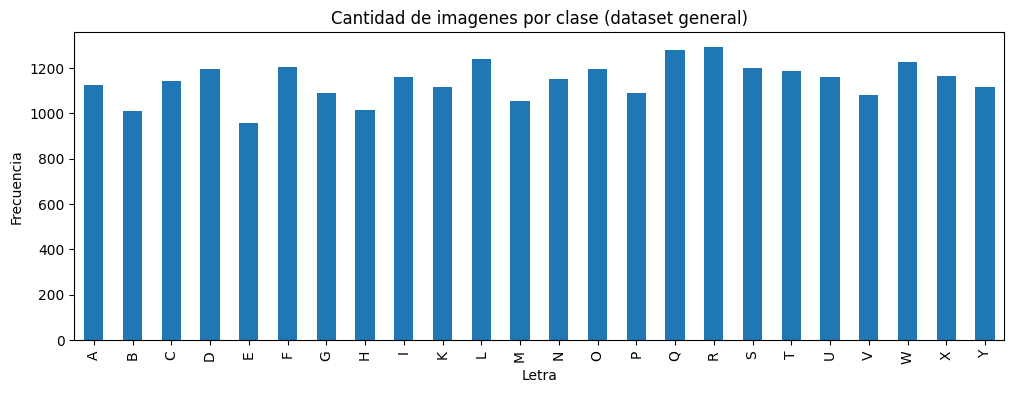

In [4]:
# Clases presentes y cantidad de imagenes por clase
clases = np.unique(y_train)
alfabeto = {i: chr(ord("A") + i) for i in range(26)}

print("Cantidad de clases:", len(clases))
print("Etiquetas:", clases.tolist())
print("Letras:", [alfabeto[c] for c in clases])
print("Letras ausentes:", [alfabeto[c] for c in range(26) if c not in clases])

conteo = pd.Series(y_train).value_counts().sort_index()
conteo.index = [alfabeto[c] for c in conteo.index]
print(conteo)

conteo.plot(kind="bar", figsize=(12, 4))
plt.title("Cantidad de imagenes por clase (dataset general)")
plt.xlabel("Letra")
plt.ylabel("Frecuencia")
plt.show()

Promedio de los pixeles: 159.29
Desviacion estandar     : 48.77
Brillo por imagen -> minimo: 54.93 | maximo: 242.55
Imagenes sin variacion: 0


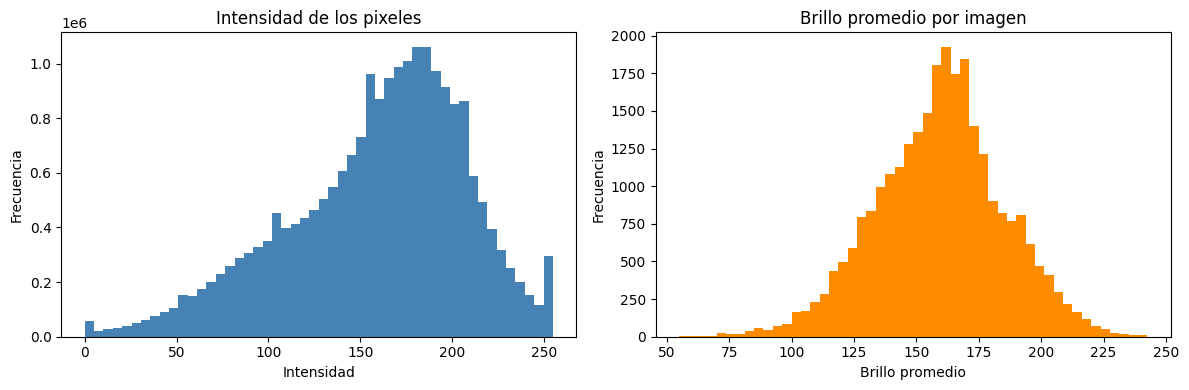

In [5]:
# Estadistica basica de los pixeles
pixeles = x_train.ravel()
brillo = x_train.mean(axis=1)

print("Promedio de los pixeles:", round(pixeles.mean(), 2))
print("Desviacion estandar     :", round(pixeles.std(), 2))
print("Brillo por imagen -> minimo:", round(brillo.min(), 2), "| maximo:", round(brillo.max(), 2))
print("Imagenes sin variacion:", (x_train.std(axis=1) == 0).sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(pixeles, bins=50, color="steelblue")
axes[0].set_title("Intensidad de los pixeles")
axes[0].set_xlabel("Intensidad")
axes[0].set_ylabel("Frecuencia")

axes[1].hist(brillo, bins=50, color="darkorange")
axes[1].set_title("Brillo promedio por imagen")
axes[1].set_xlabel("Brillo promedio")
axes[1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

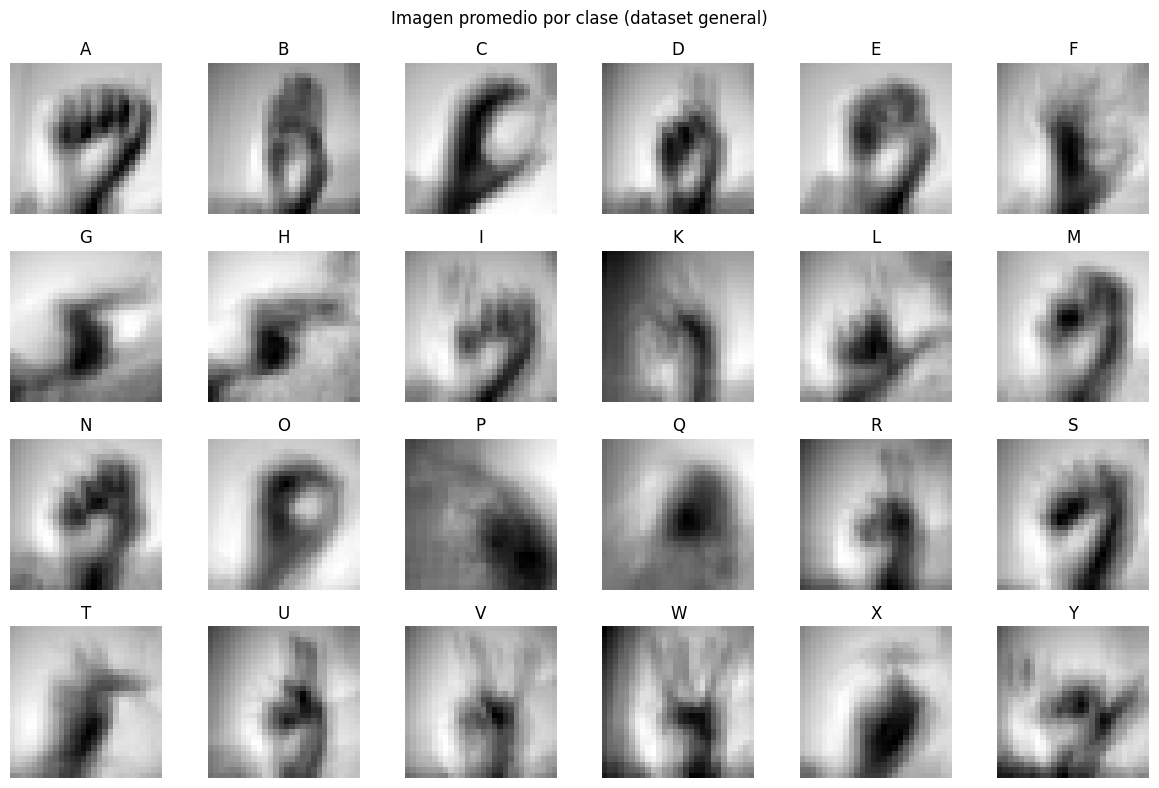

In [6]:

fig, axes = plt.subplots(4, 6, figsize=(12, 8))

for ax, etiqueta in zip(axes.ravel(), clases):
    promedio = x_train[y_train == etiqueta].mean(axis=0).reshape(28, 28)
    ax.imshow(promedio, cmap="gray",interpolation="nearest")
    ax.set_title(alfabeto[etiqueta])
    ax.axis("off")

plt.suptitle("Imagen promedio por clase (dataset general)")
plt.tight_layout()
plt.show()

In [7]:
# Duplicados exactos
print("Filas duplicadas en train:", train.duplicated().sum())
print("Filas duplicadas en test :", test.duplicated().sum())

Filas duplicadas en train: 0
Filas duplicadas en test : 0


## Variante: subconjunto de 6 letras

In [8]:

letras_similares = [0, 4, 12, 13, 18, 19]
etiquetas_nombre = {0: "A", 4: "E", 12: "M", 13: "N", 18: "S", 19: "T"}

mask_train = np.isin(y_train, letras_similares)
mask_test = np.isin(y_test, letras_similares)

x_train_filtrado = x_train[mask_train]
y_train_filtrado = y_train[mask_train]

x_test_filtrado = x_test[mask_test]
y_test_filtrado = y_test[mask_test]

mapeo_clases = {clase_orig: idx for idx, clase_orig in enumerate(letras_similares)}

y_train_mapped = np.array([mapeo_clases[val] for val in y_train_filtrado])
y_test_mapped = np.array([mapeo_clases[val] for val in y_test_filtrado])

print(f"Train filtrado: {x_train_filtrado.shape[0]:,} de {x_train.shape[0]:,} "
      f"({x_train_filtrado.shape[0] / x_train.shape[0] * 100:.1f}% del total)")
print(f"Test filtrado : {x_test_filtrado.shape[0]:,} de {x_test.shape[0]:,} "
      f"({x_test_filtrado.shape[0] / x_test.shape[0] * 100:.1f}% del total)")
print(f"Forma de los datos: {x_train_filtrado.shape} | Clases mapeadas: {sorted(mapeo_clases.values())}")
print(f"Conteo por clase (train): "
      f"{dict(zip([etiquetas_nombre[c] for c in letras_similares], np.bincount(y_train_mapped).tolist()))}")

Train filtrado: 6,674 de 27,455 (24.3% del total)
Test filtrado : 2,008 de 7,172 (28.0% del total)
Forma de los datos: (6674, 784) | Clases mapeadas: [0, 1, 2, 3, 4, 5]
Conteo por clase (train): {'A': 1126, 'E': 957, 'M': 1055, 'N': 1151, 'S': 1199, 'T': 1186}


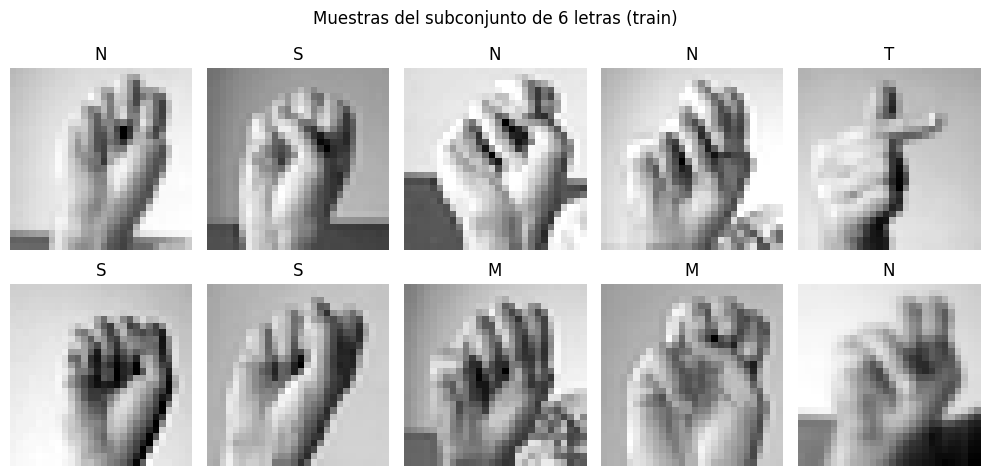

In [9]:
fig, ax = plt.subplots(2, 5, figsize=(10, 5))
for i, a in enumerate(ax.ravel()):
    a.imshow(x_train_filtrado[i].reshape(28, 28), cmap="gray")
    a.set_title(etiquetas_nombre[y_train_filtrado[i]])
    a.axis("off")
plt.suptitle("Muestras del subconjunto de 6 letras (train)")
plt.tight_layout()
plt.show()

utilizando matplotlib para visualizar diez ejemplos representativos del conjunto de datos donde se realiza la remodelacion de vectores a matrices (28x28)

Cada instancia almacenada originalmente como un vector plano de 784 características es convertida nuevamente a su matriz espacial original mediante .reshape(28, 28) para permitir su renderizado como imagen en escala de grises

A través de la visualización nos permiten apreciar tanto las características estructurales del dataset Sign MNIST, destacando la variabilidad en la postura de la mano, la iluminación y la cercanía al encuadre, lo cual nos da entender la complejidad del problema de clasificación que a de resolver el modelo de Perceptrón Multicapa

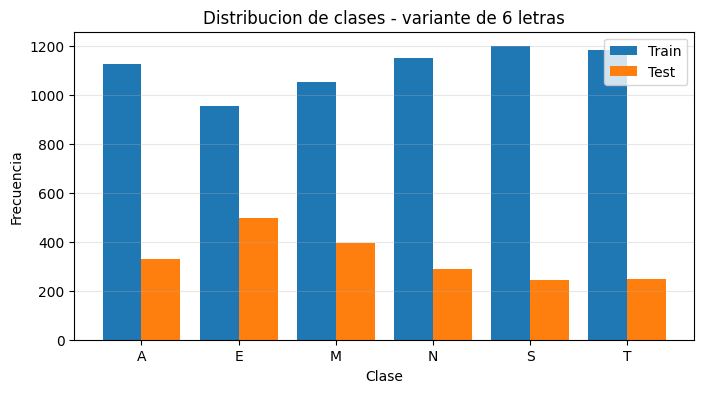

In [10]:
nombres_orden = [etiquetas_nombre[c] for c in letras_similares]

conteo_sub_train = (
    pd.Series([nombres_orden[v] for v in y_train_mapped])
    .value_counts()
    .reindex(nombres_orden)
)
conteo_sub_test = (
    pd.Series([nombres_orden[v] for v in y_test_mapped])
    .value_counts()
    .reindex(nombres_orden)
)

xpos = np.arange(len(nombres_orden))
ancho = 0.4

plt.figure(figsize=(8, 4))
plt.bar(xpos - ancho / 2, conteo_sub_train.values, ancho, label="Train")
plt.bar(xpos + ancho / 2, conteo_sub_test.values, ancho, label="Test")
plt.xticks(xpos, nombres_orden)
plt.title("Distribucion de clases - variante de 6 letras")
plt.xlabel("Clase")
plt.ylabel("Frecuencia")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

En esta parte del codigo visualizamos la frecuencia de cada etiqueta o clase en el conjunto de entrenamiento filtrado, ordenandolo secuencialmente para mejor entendimiento

El gráfico de barras muestra las frecuencias correspondientes a las seis clases analizadas (0, 4, 12, 13, 18 y 19). Se observa una distribución relativamente equilibrada entre las categorías, donde cada una ronda aproximadamente entre las 950 y 1,200 muestras de entrenamiento

Este equilibrio es un factor a tomar en cuenta para el aprendizaje de un Perceptrón Multicapa (MLP). Al no existir un desbalance severo de clases (clases mayoritarias que dominen el entrenamiento frente a otras con muy pocos registros), se reduce el riesgo de que el modelo sufra de sesgos predictivos importantes hacia una categoría en particular, permitiendo que las métricas globales como el Accuracy reflejen el desempeño real de la red neuronal

## preparacion de datos

In [11]:
# Semilla fija para que los resultados se puedan repetir
semilla = 123
random.seed(semilla)
np.random.seed(semilla)
tf.random.set_seed(semilla)


def preparar_datos(x_train, y_train, x_test, y_test, semilla=123):
    x_train_norm = x_train / 255.0
    x_test_norm = x_test / 255.0

    y_train_cat = to_categorical(y_train, num_classes=6)
    y_test_cat = to_categorical(y_test, num_classes=6)

    x_tr, x_val, y_tr, y_val = train_test_split(
        x_train_norm,
        y_train_cat,
        test_size=0.2,
        random_state=semilla,
        stratify=y_train_cat
    )

    x_tr_cnn = x_tr.reshape(-1, 28, 28, 1)
    x_val_cnn = x_val.reshape(-1, 28, 28, 1)
    x_test_cnn = x_test_norm.reshape(-1, 28, 28, 1)

    return (x_train_norm, x_test_norm, y_train_cat, y_test_cat,
            x_tr, x_val, y_tr, y_val,
            x_tr_cnn, x_val_cnn, x_test_cnn)


(x_train, x_test, y_train_cat, y_test_cat,
 x_tr, x_val, y_tr, y_val,
 x_tr_cnn, x_val_cnn, x_test_cnn) = preparar_datos(
    x_train_filtrado, y_train_mapped, x_test_filtrado, y_test_mapped, semilla=semilla
)

print("Train MLP:", x_tr.shape)
print("Val MLP  :", x_val.shape)
print("Test MLP :", x_test.shape)
print("Train CNN:", x_tr_cnn.shape)
print("Val CNN  :", x_val_cnn.shape)
print("Test CNN :", x_test_cnn.shape)

Train MLP: (5339, 784)
Val MLP  : (1335, 784)
Test MLP : (2008, 784)
Train CNN: (5339, 28, 28, 1)
Val CNN  : (1335, 28, 28, 1)
Test CNN : (2008, 28, 28, 1)


**Preparación de datos para la CNN**

Este bloque de código se encarga de normalizar las imágenes, codificar las etiquetas, dividir el conjunto de entrenamiento para validación y adaptar la forma de los tensores para la red neuronal convolucional.

**Normalizacion de datos:**

Por un lado se divide todos los valores de los píxeles de las imágenes (que originalmente van de 0 a 255) entre 255.0.
Lo que permite escalar los datos al rango 0 y 1. Esto es fundamental en Deep Learning porque facilita la convergencia del algoritmo de optimización (como Adam o SGD), evitando que valores grandes de píxeles saturen las funciones de activación y acelerando el entrenamiento por descenso de gradiente

**Codificacion de etiquetas(one-hot):**

Tambien se convierte las etiquetas numéricas de las clases (por ejemplo, números enteros de 0 a 5 para las 6 clases) en vectores binarios de tipo one-hot encoding
ya que las capas de salida de las CNNs con clasificación multiclase suelen usar una función de activación softmax que emite probabilidades para cada una de las clases. Para calcular la pérdida (loss) mediante entropía cruzada categórica (categorical crossentropy), las etiquetas reales deben tener la misma estructura vectorial.

**Division de datos de entrenamiento y validacion:**

Se parte el conjunto de entrenamiento en dos subconjuntos: uno para entrenar (80%) y otro para validar (20%)

Ademas, se hizo uso de stratify para asegurar que la proporción de cada una de las 6 clases sea idéntica tanto en el conjunto de entrenamiento como en el de validación, previniendo sesgos por desbalanceo de clases
tambien se fija la una semilla aleatoria para asegurar la reproducibilidad de los resultados en cada ejecución

**Adaptación dimensional para la CNN**

Por ultimo adaptamos las dimensiones de los datos. Ya que las imágenes originalmente estaban aplanadas como vectores de 784 características ((6674, 784) debido a matrices de 28x28). El método reshape las reconstruye a una estructura de 4 dimensiones requerida por las capas Conv2D: (número_de_muestras, alto, ancho, canales).

Cada valor indicaria lo siguiente:

-1: Calcula automáticamente el número total de muestras disponibles.

28, 28: Define el alto y ancho espacial de la imagen en formato matricial para que los filtros convolucionales puedan aplicar operaciones espaciales (kernel).

1: Indica el número de canales de color. En este caso es 1 porque las imágenes son en escala de grises (si fueran RGB, sería 3)

## Modelo Base

In [12]:
def graficar_historial(history, titulo):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))


    ax1.plot(history.history['loss'], label='Train Loss')
    ax1.plot(history.history['val_loss'], label='Val Loss')
    ax1.set_title(f'Pérdida - {titulo}')
    ax1.set_xlabel('Época')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True)


    ax2.plot(history.history['accuracy'], label='Train Acc')
    ax2.plot(history.history['val_accuracy'], label='Val Acc')
    ax2.set_title(f'Precisión - {titulo}')
    ax2.set_xlabel('Época')
    ax2.set_ylabel('Accuracy')
    ax2.legend()
    ax2.grid(True)

    plt.tight_layout()
    plt.show()

In [13]:
def evaluar_modelo_completo(model, history, x_test, y_test_cat, titulo):
    graficar_historial(history, titulo)

    y_pred_probs = model.predict(x_test, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = np.argmax(y_test_cat, axis=1)
    test_loss, test_acc = model.evaluate(x_test, y_test_cat, verbose=0)

    print(f"\n================ RESUMEN DE EVALUACIÓN: {titulo} ================")
    print(f"Test Accuracy:        {test_acc * 100:.2f}%")
    print(f"Test Loss:            {test_loss:.4f}")
    print(f"=================================================================\n")


    nombres_letras = ['A', 'E', 'M', 'N', 'S', 'T']
    print(classification_report(y_true, y_pred, target_names=nombres_letras))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 4.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=nombres_letras, yticklabels=nombres_letras)
    plt.xlabel('Predicción del Modelo')
    plt.ylabel('Clase Real')
    plt.title(f'Matriz de Confusión - {titulo}')
    plt.show()

Realizamos 2 funciones especificas que nos permitiran automatizar los procesos de registro de modelos y ver su desempeño por un lado:

La función graficar_historial automatiza el registro y la representación gráfica del proceso de aprendizaje de la red neuronal a lo largo de las epocas, nos permite graficar de forma simultánea la evolución de la función de pérdida tanto para el conjunto de entrenamiento, como para el de validación. Permite identificar la convergencia del optimizador y detectar de manera temprana signos de sobreajuste (overfitting), el cual se manifiesta cuando la pérdida de entrenamiento sigue disminuyendo mientras la de validación comienza a incrementarse
Luego esta el grafico de Precisión, que compara la precisión obtenida en los datos de entrenamiento frente a los de validación en cada una de las epocas. facilitando la visualización de la estabilidad del aprendizaje y el porcentaje maximo de acierto alcanzado por el modelo MLP

Luego tenemos la funcion para evaluar los desempeños de los distintos modelos de forma automatiza y eficiente:

La función evaluar_modelo_completo encapsula la fase de prueba sobre los datos, calculando y reportando las métricas e interpretaciones gráficas

1. Para la inferencia y conversión de Probabilidades, obtenemos un lista de probabilidades para cada una de las 6 clases de salida calculando cada uno de sus metricas individualmente

    Tambien convierte las probabilidades de la capa Softmax (tanto en las predicciones como en las etiquetas categoricas reales) de vuelta a indices enteros o sus etiquetas reales. Esto permite alinear las predicciones de la red con las etiquetas verdaderas para el calculo de metricas vectorizadas

2. Métricas Globales (Accuracy y Loss de Prueba): Calculamos de forma independiente la pérdida final (Test Loss) y la precisión global (Test Accuracy) del modelo sobre el conjunto de pruebas no visto. Dandonos un valor porcentual para saber la efectividad general del modelo para reconocer correctamente las señas de las letras A, E, M, N, S y T

3. Para el reporte de metricas, utilizamos una lista con los nombres reales de las clases (['A', 'E', 'M', 'N', 'S', 'T']) para calcular metricas avanzadas por categoría ya sea tanto la Precision (Precisión) que es la proporción de predicciones positivas verdaderas frente al total de predicciones positivas realizadas para cada seña, midiendo cuántos falsos positivos genera el modelo

    Tambien calculamos el Recall que mide la capacidad de la red para identificar correctamente todas las instancias reales de cada clase, cuantificando los falsos negativos

    Y por ultimo el F1-Score que calcula la media entre Precision y Recall, entregando una metrica equilibrada fundamental cuando se analizan clases que comparten similitudes visuales complejas dentro de las imagenes de señas

4. Y por ultimo para el analisis generamos una matriz de confusión visual en formato de mapa de calor utilizando una paleta que nos permite identificar de manera grafica que letras especificas generan mayor nivel de confusion en el modelo debido a la similitud que estan puedan tener, logrando asi un analisis critico de errores y limitaciones de la red neuronal en el procesamiento de estas imagenes

In [14]:
def crear_cnn(filtros=32, neuronas=64, dropout=0.5,
              batchnorm=False, l2_reg=0.0, aumento=False):
    """Arma la CNN de dos bloques convolucionales.

    filtros: filtros del primer bloque (el segundo usa el doble)
    neuronas: neuronas de la capa densa antes de la salida
    dropout: porcentaje de neuronas que se apagan en el entrenamiento
    batchnorm: normaliza la salida de cada capa
    l2_reg: fuerza de la penalizacion L2 (0.0 = sin penalizacion)
    aumento: rota, desplaza y hace zoom a las imagenes durante el entrenamiento
    """
    capas = [Input(shape=(28, 28, 1))]

    # El aumento de datos solo actua cuando se entrena, no al predecir.
    # No se hacen giros horizontales porque al reflejar la mano cambia la letra.
    if aumento:
        capas += [
            RandomRotation(0.03),
            RandomTranslation(0.08, 0.08, fill_mode="nearest"),
            RandomZoom(0.08, fill_mode="nearest"),
        ]

    # Si l2_reg es 0 no se aplica ninguna penalizacion
    regularizador = l2(l2_reg) if l2_reg > 0 else None

    capas += [
        Conv2D(filtros, (3, 3), activation="relu", kernel_regularizer=regularizador),
    ]
    if batchnorm:
        capas.append(BatchNormalization())
    capas.append(MaxPooling2D((2, 2)))

    capas += [
        Conv2D(filtros * 2, (3, 3), activation="relu", kernel_regularizer=regularizador),
    ]
    if batchnorm:
        capas.append(BatchNormalization())
    capas.append(MaxPooling2D((2, 2)))

    capas += [
        Flatten(),
        Dense(neuronas, activation="relu", kernel_regularizer=regularizador),
    ]
    if batchnorm:
        capas.append(BatchNormalization())
    capas += [
        Dropout(dropout),
        Dense(6, activation="softmax"),
    ]

    return Sequential(capas)


model_cnn = crear_cnn(filtros=32, neuronas=64, dropout=0.5)
model_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,670 (475.27 KB)

 Trainable params: 121,670 (475.27 KB)

 Non-trainable params: 0 (0.00 B)

Este bloque define la arquitectura secuencial de la Red Neuronal Convolucional utilizando Keras. Su objetivo principal es extraer automáticamente características espaciales jerárquicas de las imágenes (desde bordes y líneas simples en las primeras capas hasta formas más complejas en las profundas) y realizar la clasificación final en 6 categorías distintas.

**1. Primera etapa de extracción de características (Bloque Convolucional 1)**

Se aplican 32 filtros convolucionales de tamaño 3x3 sobre la imagen de entrada.

Utiliza la función de activación ReLU para introducir no linealidad y permitir que la red aprenda patrones complejos.
El parámetro input_shape=(28, 28, 1) le indica a la red que recibirá imágenes de 28x28 píxeles con 1 solo canal (escala de grises).

Luego se utiliza un Pooling que aplica una operación de submuestreo con una ventana de 2x2. Lo que reduce a la mitad las dimensiones espaciales de la matriz, disminuyendo el costo computacional y ayudando a retener las características más relevantes.

**2. Segunda etapa de extracción de características (Bloque Convolucional 2)**

Pasando a la segunda convulicion, se duplica la capacidad de abstracción utilizando 64 filtros de 3x3. Al ser mas profunda la red, combina las características básicas de la primera capa y a su vez extrae patrones más complejos de las imagenes o del objeto.
Tambien se hace uso de Pooling que vuelve a reducir las dimensiones espaciales mediante el valor máximo local, compactando aún más la representación antes de pasar a la fase densa.

**3. Fase de clasificación (Capas Densas y Regularización)**

Aplana la salida de 3D de las matrices convolucionales anteriores transformándola en un vector unidimensional largo. Esto es necesario para conectar las características extraídas con las capas densas tradicionales (Fully Connected).

Dense(64, activation='relu'): Una capa totalmente conectada de 64 neuronas con activación ReLU que interpreta las características aplanadas y comienza a tomar decisiones lógicas sobre la categoría de la imagen.

Dropout(0.5): Capa de regularización que apaga aleatoriamente el 50% de las conexiones durante el entrenamiento, forzando a la red a no depender de neuronas específicas y a generalizar mejor. Esta fue una decision clave ya que se añadió para combatir el sobreajuste severo detectado en la primera etapa

Dense(6, activation='softmax'): Capa de salida con 6 neuronas (una para cada clase del problema). La función de activación softmax convierte los valores de salida en probabilidades que suman 1 (100%), permitiendo identificar a qué clase pertenece la imagen con mayor certeza.

El resumen de la arquitectura muestra un modelo con un total de 121,670 parámetros entrenables. Las capas convolucionales y de max pooling reducen progresivamente las dimensiones espaciales de las imágenes de entrada mientras incrementan los mapas de características hasta llegar a una forma aplanada de 1,600 valores. Finalmente, una capa densa de 64 neuronas con dropout procesa la información y una capa de salida densa con activación softmax genera la clasificación final en 6 categorías distintas.

In [15]:
model_cnn.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop_cnn = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

inicio = time.time()

history_cnn = model_cnn.fit(
    x_tr_cnn, y_tr,
    epochs=50,
    batch_size=64,
    validation_data=(x_val_cnn, y_val),
    callbacks=[early_stop_cnn],
    verbose=0
)

tiempo_cnn_base = time.time() - inicio

print(f"Epocas entrenadas: {len(history_cnn.history['loss'])}")
print(f"Tiempo de entrenamiento: {tiempo_cnn_base:.1f} s")

Epocas entrenadas: 50
Tiempo de entrenamiento: 195.2 s


Este bloque prepara el modelo para aprender, configura un mecanismo de seguridad para detener el entrenamiento si el modelo deja de mejorar (evitando sobreajuste) y ejecuta el proceso iterativo donde la red ajusta sus pesos internos a lo largo de 50 épocas utilizando los datos de entrenamiento y validación

**1. Compilación del modelo**

Utiliza el optimizador Adam (Adaptive Moment Estimation), un algoritmo eficiente de descenso de gradiente que ajusta automáticamente la tasa de aprendizaje para cada parámetro, logrando una convergencia rápida y estable.

Tambien se define la función de pérdida(categorical_crossentropy) para evaluar qué tan equivocadas están las predicciones de la red frente a las etiquetas reales. Es la métrica estándar para problemas de clasificación multiclase.

Por ultimo se configura la métrica de control que se evaluará en cada época, midiendo el porcentaje de imágenes clasificadas correctamente.

**2. Configuración de Early Stopping**

Actúa como un supervisor del entrenamiento. Monitorea la pérdida en la validación (val_loss). Si durante 10 épocas consecutivas (patience=10) esta pérdida no mejora, el entrenamiento se detiene de manera automáticamente.
Garantiza que, al detenerse, el modelo recupere y conserve los pesos exactos de la época que obtuvo el mejor resultado de validación, evitando que empeore si empieza a sobreajustarse al final.

**3. Ejecución del Entrenamiento (Fit)**

Por ultimo se pasaria a la fase de entrenamiento,donde se establece el límite máximo de pasadas completas que el modelo hará sobre todo el conjunto de entrenamiento siendo de 50 epocas.

Se define un tamaño de lotes que se procesarán en bloques de 64 en 64 antes de actualizar los pesos de la red.

Tambien se evaluara el desempeño del modelo con el conjunto de validación (x_val_cnn, y_val) al final de cada época para medir su capacidad de generalización. Junto con esto se integra la regla del early stopping en el bucle de entrenamiento.

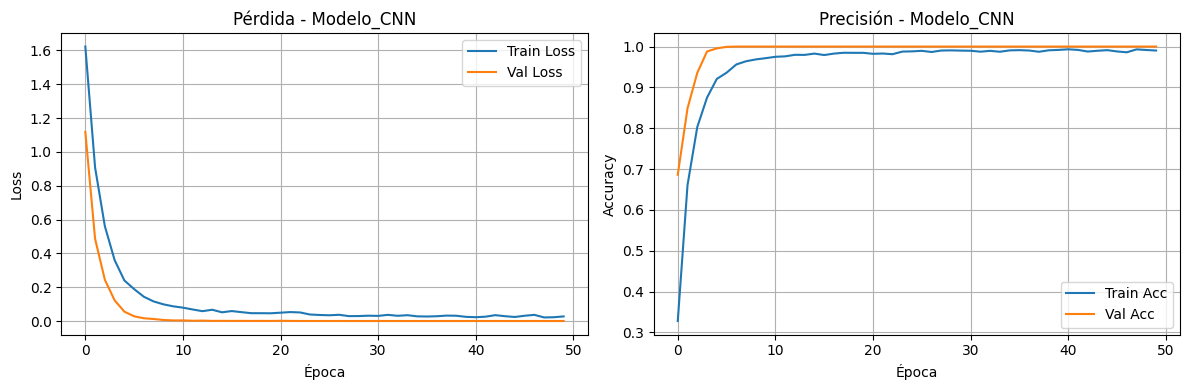


================ RESUMEN DE EVALUACIÓN: Modelo_CNN ================
Test Accuracy:        91.09%
Test Loss:            0.5092

              precision    recall  f1-score   support

           A       0.89      1.00      0.94       331
           E       1.00      0.93      0.96       498
           M       0.94      0.90      0.92       394
           N       0.91      0.71      0.80       291
           S       0.77      1.00      0.87       246
           T       0.92      0.92      0.92       248

    accuracy                           0.91      2008
   macro avg       0.90      0.91      0.90      2008
weighted avg       0.92      0.91      0.91      2008



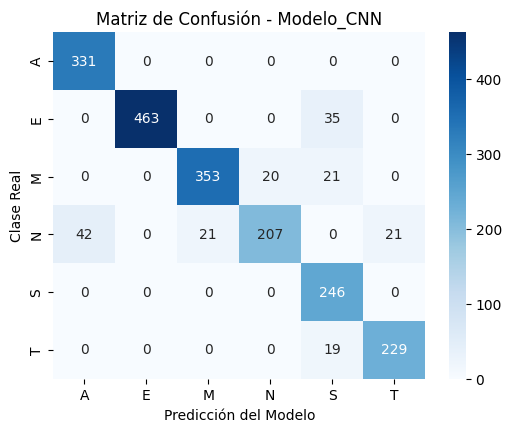

In [16]:
evaluar_modelo_completo(model_cnn, history_cnn, x_test_cnn, y_test_cat, "Modelo_CNN")

**Evaluacion del Modelo entrenado:**

Este bloque evalúa el rendimiento general y detallado del modelo ya entrenado. Su objetivo es comprobar la capacidad de generalización de la CNN mediante curvas de aprendizaje, métricas globales (accuracy, loss), un reporte de clasificación por clase (precision, recall, f1-score) y una matriz de confusión visual

## MLP base (punto de comparacion)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epocas entrenadas: 31
Tiempo de entrenamiento: 14.8 s


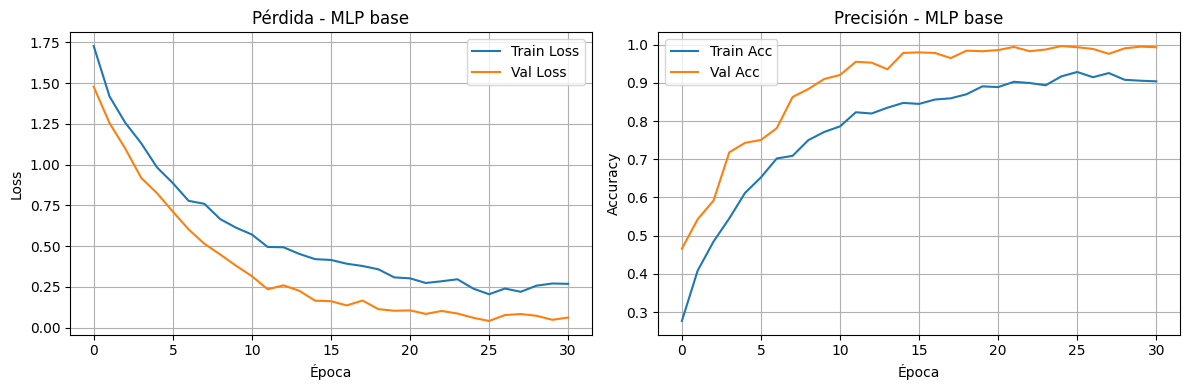


================ RESUMEN DE EVALUACIÓN: MLP base ================
Test Accuracy:        78.29%
Test Loss:            0.7550

              precision    recall  f1-score   support

           A       0.88      0.96      0.92       331
           E       0.87      0.90      0.88       498
           M       0.83      0.61      0.70       394
           N       0.68      0.60      0.64       291
           S       0.50      0.58      0.54       246
           T       0.81      1.00      0.90       248

    accuracy                           0.78      2008
   macro avg       0.76      0.78      0.76      2008
weighted avg       0.79      0.78      0.78      2008



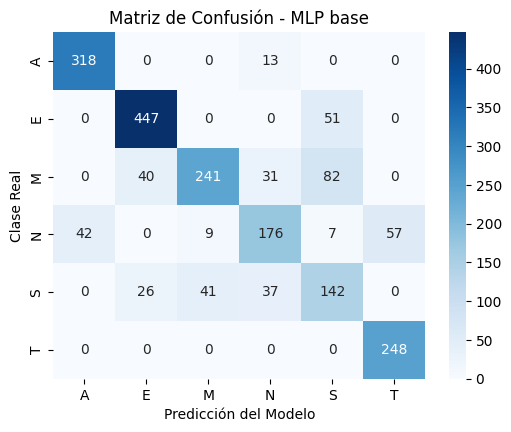

In [17]:
def crear_mlp(neuronas=128, dropout=0.3):
    modelo = Sequential([
        Dense(neuronas, activation="relu", input_shape=(784,)),
        Dropout(dropout),
        Dense(neuronas // 2, activation="relu"),
        Dropout(dropout),
        Dense(6, activation="softmax")
    ])
    return modelo


modelo_mlp_base = crear_mlp(neuronas=128, dropout=0.3)
modelo_mlp_base.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

parada = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

inicio = time.time()
historial_mlp_base = modelo_mlp_base.fit(
    x_tr, y_tr,
    epochs=40,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=[parada],
    verbose=0
)
tiempo_mlp_base = time.time() - inicio

print(f"Epocas entrenadas: {len(historial_mlp_base.history['loss'])}")
print(f"Tiempo de entrenamiento: {tiempo_mlp_base:.1f} s")

evaluar_modelo_completo(modelo_mlp_base, historial_mlp_base, x_test, y_test_cat, "MLP base")

In [18]:
def entrenar_y_medir(modelo, x_tr, y_tr, x_val, y_val, epocas=12):
    """Entrena el modelo y devuelve su mejor accuracy de validacion."""
    modelo.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    historial = modelo.fit(
        x_tr, y_tr,
        epochs=epocas,
        batch_size=64,
        validation_data=(x_val, y_val),
        verbose=0
    )
    return max(historial.history["val_accuracy"])


# Grid search: probamos todas las combinaciones de la lista
resultados_grid_mlp = []

for neuronas in [64, 128, 256]:
    for dropout in [0.2, 0.5]:
        acc = entrenar_y_medir(crear_mlp(neuronas, dropout), x_tr, y_tr, x_val, y_val)
        resultados_grid_mlp.append({
            "neuronas": neuronas,
            "dropout": dropout,
            "val_accuracy": acc,
        })

tabla_grid_mlp = pd.DataFrame(resultados_grid_mlp).sort_values(
    "val_accuracy", ascending=False
)
display(tabla_grid_mlp)

mejores_mlp = tabla_grid_mlp.iloc[0]
print("Mejor MLP:", int(mejores_mlp["neuronas"]), "neuronas |",
      "dropout", mejores_mlp["dropout"], "| val_accuracy",
      round(mejores_mlp["val_accuracy"], 4))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


,neuronas,dropout,val_accuracy
4,256,0.2,0.987266
2,128,0.2,0.981273
0,64,0.2,0.856180
5,256,0.5,0.784270
1,64,0.5,0.493633
3,128,0.5,0.379026


Mejor MLP: 256 neuronas | dropout 0.2 | val_accuracy 0.9873


In [19]:
resultados_grid_cnn = []

for filtros in [16, 32, 64]:
    for dropout in [0.2, 0.5]:
        acc = entrenar_y_medir(crear_cnn(filtros, 64, dropout),
                              x_tr_cnn, y_tr, x_val_cnn, y_val)
        resultados_grid_cnn.append({
            "filtros": filtros,
            "dropout": dropout,
            "val_accuracy": acc,
        })

tabla_grid_cnn = pd.DataFrame(resultados_grid_cnn).sort_values(
    "val_accuracy", ascending=False
)
display(tabla_grid_cnn)

mejores_cnn = tabla_grid_cnn.iloc[0]
print("Mejor CNN:", int(mejores_cnn["filtros"]), "filtros |",
      "dropout", mejores_cnn["dropout"], "| val_accuracy",
      round(mejores_cnn["val_accuracy"], 4))

,filtros,dropout,val_accuracy
0,16,0.2,1.0
1,16,0.5,1.0
2,32,0.2,1.0
3,32,0.5,1.0
4,64,0.2,1.0
5,64,0.5,1.0


Mejor CNN: 16 filtros | dropout 0.2 | val_accuracy 1.0


In [20]:
def entrenar_final(modelo, x_tr, y_tr, x_val, y_val, nombre):
    """Entrena con early stopping y devuelve el historial y el tiempo usado."""
    modelo.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    parada = EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)

    inicio = time.time()
    historial = modelo.fit(
        x_tr, y_tr,
        epochs=50,
        batch_size=64,
        validation_data=(x_val, y_val),
        callbacks=[parada],
        verbose=0
    )
    tiempo = time.time() - inicio

    print(f"{nombre}: {len(historial.history['loss'])} epocas | {tiempo:.1f} s")
    return historial, tiempo


modelo_mlp_optimo = crear_mlp(int(mejores_mlp["neuronas"]), mejores_mlp["dropout"])
historial_mlp_optimo, tiempo_mlp_optimo = entrenar_final(
    modelo_mlp_optimo, x_tr, y_tr, x_val, y_val, "MLP optimizada"
)

modelo_cnn_optimo = crear_cnn(int(mejores_cnn["filtros"]), 64, mejores_cnn["dropout"])
historial_cnn_optimo, tiempo_cnn_optimo = entrenar_final(
    modelo_cnn_optimo, x_tr_cnn, y_tr, x_val_cnn, y_val, "CNN optimizada"
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


MLP optimizada: 31 epocas | 18.5 s
CNN optimizada: 50 epocas | 99.3 s


## Comparacion MLP vs CNN

In [21]:
def accuracy_test(modelo, x, y):
    _, acc = modelo.evaluate(x, y, verbose=0)
    return acc


comparacion = pd.DataFrame([
    {
        "modelo": "MLP base",
        "val_accuracy": max(historial_mlp_base.history["val_accuracy"]),
        "test_accuracy": accuracy_test(modelo_mlp_base, x_test, y_test_cat),
        "parametros": modelo_mlp_base.count_params(),
        "tiempo_s": tiempo_mlp_base,
    },
    {
        "modelo": "MLP optimizada",
        "val_accuracy": max(historial_mlp_optimo.history["val_accuracy"]),
        "test_accuracy": accuracy_test(modelo_mlp_optimo, x_test, y_test_cat),
        "parametros": modelo_mlp_optimo.count_params(),
        "tiempo_s": tiempo_mlp_optimo,
    },
    {
        "modelo": "CNN base",
        "val_accuracy": max(history_cnn.history["val_accuracy"]),
        "test_accuracy": accuracy_test(model_cnn, x_test_cnn, y_test_cat),
        "parametros": model_cnn.count_params(),
        "tiempo_s": tiempo_cnn_base,
    },
    {
        "modelo": "CNN optimizada",
        "val_accuracy": max(historial_cnn_optimo.history["val_accuracy"]),
        "test_accuracy": accuracy_test(modelo_cnn_optimo, x_test_cnn, y_test_cat),
        "parametros": modelo_cnn_optimo.count_params(),
        "tiempo_s": tiempo_cnn_optimo,
    },
])

comparacion = comparacion.round({"val_accuracy": 4, "test_accuracy": 4, "tiempo_s": 1})
display(comparacion)

,modelo,val_accuracy,test_accuracy,parametros,tiempo_s
0,MLP base,0.9963,0.7829,109126,14.8
1,MLP optimizada,1.0000,0.8162,234630,18.5
2,CNN base,1.0000,0.9109,121670,195.2
3,CNN optimizada,1.0000,0.9198,56454,99.3


In [22]:
# Partimos de la mejor cantidad de filtros que dio el grid search
filtros_base = int(mejores_cnn["filtros"])

# Cada variante agrega una tecnica sobre la anterior
variantes = [
    {"nombre": "Sin regularizacion", "dropout": 0.0, "batchnorm": False, "l2_reg": 0.0,  "aumento": False},
    {"nombre": "+ Dropout",          "dropout": 0.5, "batchnorm": False, "l2_reg": 0.0,  "aumento": False},
    {"nombre": "+ BatchNorm",        "dropout": 0.5, "batchnorm": True,  "l2_reg": 0.0,  "aumento": False},
    {"nombre": "+ L2",               "dropout": 0.5, "batchnorm": True,  "l2_reg": 1e-4, "aumento": False},
    {"nombre": "+ Aumento de datos", "dropout": 0.5, "batchnorm": True,  "l2_reg": 1e-4, "aumento": True},
]

resultados = []

for v in variantes:
    modelo = crear_cnn(filtros_base, 64, v["dropout"],
                       v["batchnorm"], v["l2_reg"], v["aumento"])
    modelo.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    parada = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

    inicio = time.time()
    historial = modelo.fit(
        x_tr_cnn, y_tr,
        epochs=30,
        batch_size=64,
        validation_data=(x_val_cnn, y_val),
        callbacks=[parada],
        verbose=0
    )
    tiempo = time.time() - inicio

    # evaluate devuelve [perdida, accuracy]
    _, acc_train = modelo.evaluate(x_tr_cnn, y_tr, verbose=0)
    _, acc_val = modelo.evaluate(x_val_cnn, y_val, verbose=0)
    loss_test, acc_test = modelo.evaluate(x_test_cnn, y_test_cat, verbose=0)

    resultados.append({
        "modelo": modelo,
        "variante": v["nombre"],
        "dropout": v["dropout"],
        "batchnorm": "si" if v["batchnorm"] else "no",
        "l2": v["l2_reg"],
        "aumento": "si" if v["aumento"] else "no",
        "acc_train": acc_train,
        "acc_val": acc_val,
        "acc_test": acc_test,
        "loss_test": loss_test,
        "gap": acc_train - acc_val,
        "parametros": modelo.count_params(),
        "epocas": len(historial.history["loss"]),
        "tiempo_s": tiempo,
        "historial": historial,
    })

    print(f"{v['nombre']:18} | train {acc_train:.4f} | val {acc_val:.4f} | "
          f"test {acc_test:.4f} | gap {acc_train - acc_val:.4f} | {tiempo:.1f} s")

Sin regularizacion | train 1.0000 | val 1.0000 | test 0.9407 | gap 0.0000 | 61.9 s
+ Dropout          | train 1.0000 | val 1.0000 | test 0.9124 | gap 0.0000 | 58.5 s
+ BatchNorm        | train 1.0000 | val 1.0000 | test 0.9128 | gap 0.0000 | 81.2 s
+ L2               | train 1.0000 | val 1.0000 | test 0.8914 | gap 0.0000 | 93.2 s
+ Aumento de datos | train 0.9978 | val 0.9978 | test 0.9935 | gap -0.0000 | 55.3 s


,variante,dropout,batchnorm,l2,aumento,acc_train,acc_val,acc_test,loss_test,gap,parametros,epocas,tiempo_s
0,Sin regularizacion,0.0,no,0.0000,no,1.0000,1.0000,0.9407,0.4225,0.0,56454,30,61.9
1,+ Dropout,0.5,no,0.0000,no,1.0000,1.0000,0.9124,0.5093,0.0,56454,30,58.5
2,+ BatchNorm,0.5,si,0.0000,no,1.0000,1.0000,0.9128,0.2995,0.0,56902,29,81.2
3,+ L2,0.5,si,0.0001,no,1.0000,1.0000,0.8914,0.5882,0.0,56902,30,93.2
4,+ Aumento de datos,0.5,si,0.0001,si,0.9978,0.9978,0.9935,0.0333,-0.0,56902,18,55.3


Mejor variante en test: + Aumento de datos


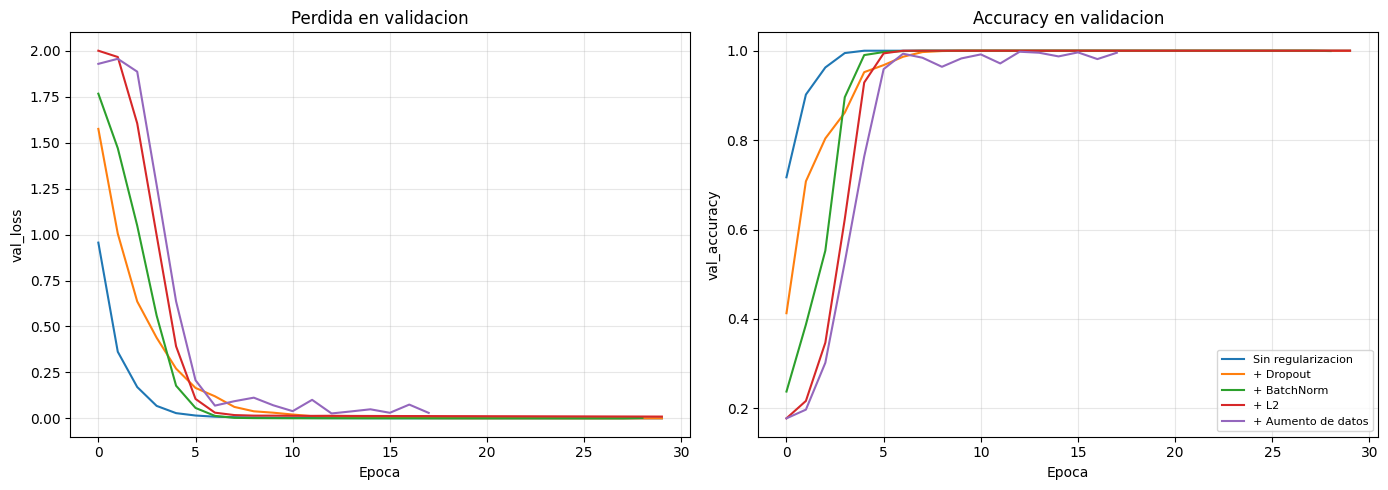

In [23]:
tabla_regularizacion = pd.DataFrame(resultados).drop(columns=["historial", "modelo"])
tabla_regularizacion = tabla_regularizacion.round({
    "acc_train": 4,
    "acc_val": 4,
    "acc_test": 4,
    "loss_test": 4,
    "gap": 4,
    "tiempo_s": 1,
})
display(tabla_regularizacion)

print("Mejor variante en test:",
      tabla_regularizacion.loc[tabla_regularizacion["acc_test"].idxmax(), "variante"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for fila in resultados:
    historial = fila["historial"].history
    axes[0].plot(historial["val_loss"], label=fila["variante"])
    axes[1].plot(historial["val_accuracy"], label=fila["variante"])

axes[0].set_title("Perdida en validacion")
axes[0].set_xlabel("Epoca")
axes[0].set_ylabel("val_loss")
axes[0].grid(alpha=0.3)

axes[1].set_title("Accuracy en validacion")
axes[1].set_xlabel("Epoca")
axes[1].set_ylabel("val_accuracy")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Análisis detallado de los errores

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
Total de aciertos: 1847
Total de errores: 161


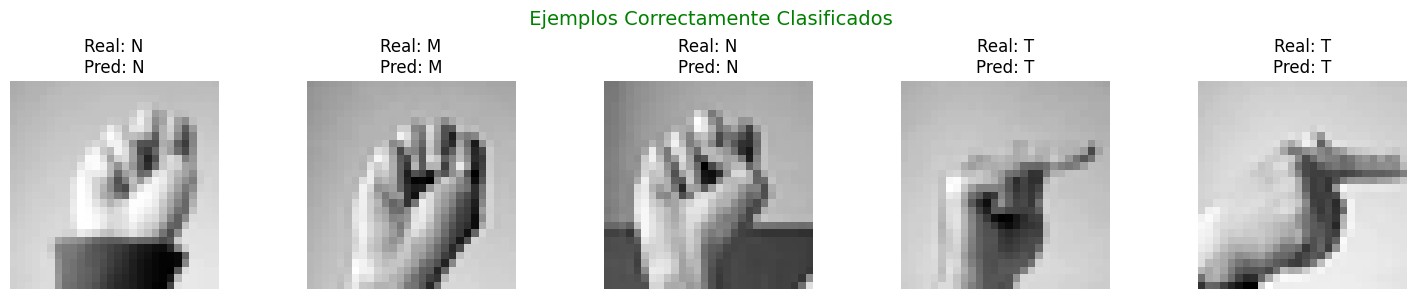

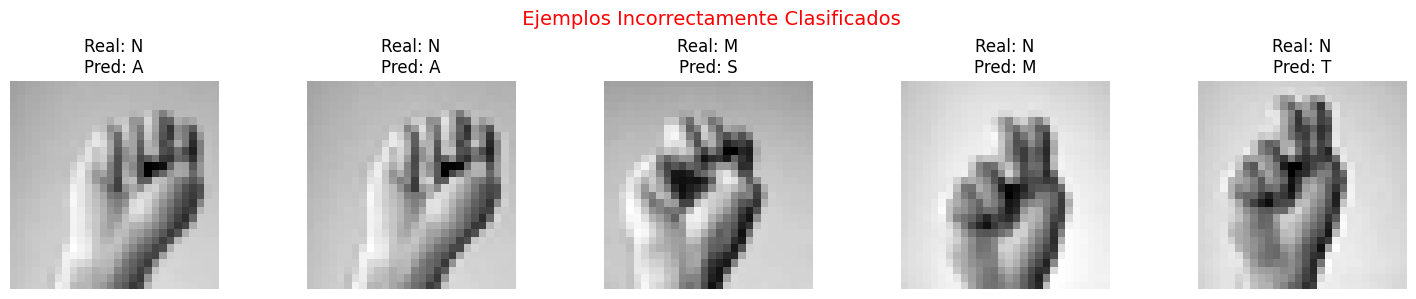

In [24]:
y_pred_probs = modelo_cnn_optimo.predict(x_test_cnn)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(y_test_cat, axis=1)


nombres_letras = ['A', 'E', 'M', 'N', 'S', 'T']


correct_idx = np.where(y_pred == y_true)[0]
incorrect_idx = np.where(y_pred != y_true)[0]

print(f"Total de aciertos: {len(correct_idx)}")
print(f"Total de errores: {len(incorrect_idx)}")


n_muestras = 5
muestras_correctas = np.random.choice(correct_idx, n_muestras, replace=False)
muestras_errores = np.random.choice(incorrect_idx, n_muestras, replace=False)


def mostrar_predicciones(indices, titulo, color_titulo='black'):
    fig, axes = plt.subplots(1, len(indices), figsize=(15, 3))
    fig.suptitle(titulo, fontsize=14, color=color_titulo)
    for i, idx in enumerate(indices):
        img = x_test[idx].reshape(28, 28)
        axes[i].imshow(img, cmap='gray')
        axes[i].set_title(f'Real: {nombres_letras[y_true[idx]]}\nPred: {nombres_letras[y_pred[idx]]}')
        axes[i].axis('off')
    plt.tight_layout()
    plt.show()

# 6. Mostrar ejemplos
mostrar_predicciones(muestras_correctas, ' Ejemplos Correctamente Clasificados', 'green')
mostrar_predicciones(muestras_errores, ' Ejemplos Incorrectamente Clasificados', 'red')

Este bloque realiza un análisis detallado de los errores y aciertos del modelo entrenado utilizando el conjunto de prueba (test). Su objetivo principal es separar las predicciones correctas de las incorrectas, cuantificarlas y seleccionar muestras aleatorias de ambos grupos para visualizarlas gráficamente, permitiendo entender visualmente en qué se equivoca la red.

Primero se pasa todo el conjunto de prueba por el modelo para obtener las probabilidades de cada clase (y_pred_probs). Luego, utiliza np.argmax para extraer la clase con mayor probabilidad tanto en las predicciones (y_pred) como en las etiquetas reales codificadas en one-hot (y_true), y define la lista con los nombres de las letras correspondientes.

Se Compara las predicciones de la red con las etiquetas reales. Almacena los índices donde el modelo acertó en correct_idx y donde falló en incorrect_idx, imprimiendo el conteo total de ambos grupos.

Por ultimo se seleccionan aleatoriamente 5 ejemplos de aciertos y 5 de errores sin repetición. La función mostrar_predicciones genera una fila de gráficos donde se muestra la imagen en escala de grises junto con un título que indica claramente cuál era la letra real y qué letra predijo erróneamente el modelo

In [25]:
letras = ["A", "E", "M", "N", "S", "T"]


def metricas_completas(modelo, x, y_cat, nombre):
    """Calcula varias metricas del modelo sobre el conjunto de prueba."""
    probs = modelo.predict(x, verbose=0)
    y_pred = np.argmax(probs, axis=1)
    y_true = np.argmax(y_cat, axis=1)
    perdida, _ = modelo.evaluate(x, y_cat, verbose=0)

    return {
        "modelo": nombre,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "roc_auc_macro": roc_auc_score(y_cat, probs, average="macro", multi_class="ovr"),
        "loss_test": perdida,
    }


modelos_evaluar = [
    ("MLP base", modelo_mlp_base, x_test),
    ("MLP optimizada", modelo_mlp_optimo, x_test),
    ("CNN base", model_cnn, x_test_cnn),
    ("CNN optimizada", modelo_cnn_optimo, x_test_cnn),
]

filas = [metricas_completas(m, x, y_test_cat, nombre) for nombre, m, x in modelos_evaluar]

# Agregamos la mejor variante de la ablacion de regularizacion
mejor_regularizada = max(resultados, key=lambda f: f["acc_test"])
filas.append(metricas_completas(
    mejor_regularizada["modelo"], x_test_cnn, y_test_cat,
    "CNN " + mejor_regularizada["variante"]
))

tabla_metricas = pd.DataFrame(filas).set_index("modelo").round(4)
display(tabla_metricas)

print("Mejor F1 macro :", tabla_metricas["f1_macro"].idxmax(),
      round(tabla_metricas["f1_macro"].max(), 4))
print("Mejor ROC-AUC  :", tabla_metricas["roc_auc_macro"].idxmax(),
      round(tabla_metricas["roc_auc_macro"].max(), 4))
print("Diferencia de F1 entre CNN y MLP optimizadas:",
      round(tabla_metricas.loc["CNN optimizada", "f1_macro"]
            - tabla_metricas.loc["MLP optimizada", "f1_macro"], 4))

,accuracy,precision_macro,recall_macro,f1_macro,roc_auc_macro,loss_test
modelo,,,,,,
MLP base,0.7829,0.7641,0.7753,0.7642,0.9532,0.7550
MLP optimizada,0.8162,0.8005,0.8047,0.7952,0.9581,0.7446
CNN base,0.9109,0.9042,0.9101,0.9016,0.9923,0.5092
CNN optimizada,0.9198,0.9200,0.9131,0.9127,0.9905,0.4658
CNN + Aumento de datos,0.9935,0.9945,0.9948,0.9946,1.0000,0.0333


Mejor F1 macro : CNN + Aumento de datos 0.9946
Mejor ROC-AUC  : CNN + Aumento de datos 1.0
Diferencia de F1 entre CNN y MLP optimizadas: 0.1175


In [26]:
mapa_modelos = {nombre: modelo for nombre, modelo, _ in modelos_evaluar}
mapa_modelos["CNN " + mejor_regularizada["variante"]] = mejor_regularizada["modelo"]

# El mejor F1 macro es el que mejor equilibra las seis letras
nombre_final = tabla_metricas["f1_macro"].idxmax()
modelo_final = mapa_modelos[nombre_final]
x_test_final = x_test if "MLP" in nombre_final else x_test_cnn

probs_final = modelo_final.predict(x_test_final, verbose=0)
y_pred_final = np.argmax(probs_final, axis=1)
y_true_final = np.argmax(y_test_cat, axis=1)

print("Modelo final:", nombre_final)
print("Parametros:", modelo_final.count_params())
print("Accuracy en test:", round(tabla_metricas.loc[nombre_final, "accuracy"], 4))
print("F1 macro:", round(tabla_metricas.loc[nombre_final, "f1_macro"], 4))

Modelo final: CNN + Aumento de datos
Parametros: 56902
Accuracy en test: 0.9935
F1 macro: 0.9946


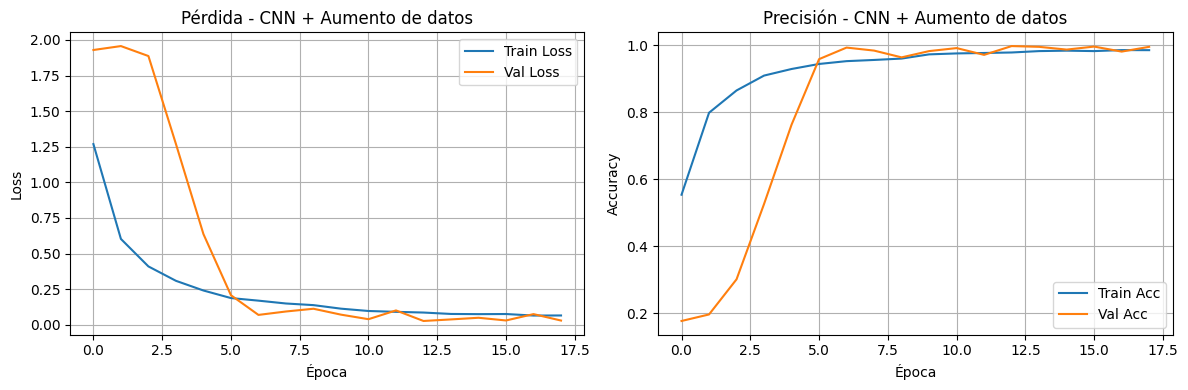


================ RESUMEN DE EVALUACIÓN: CNN + Aumento de datos ================
Test Accuracy:        99.35%
Test Loss:            0.0333

              precision    recall  f1-score   support

           A       1.00      1.00      1.00       331
           E       1.00      0.98      0.99       498
           M       0.97      1.00      0.98       394
           N       1.00      0.99      0.99       291
           S       1.00      1.00      1.00       246
           T       1.00      1.00      1.00       248

    accuracy                           0.99      2008
   macro avg       0.99      0.99      0.99      2008
weighted avg       0.99      0.99      0.99      2008



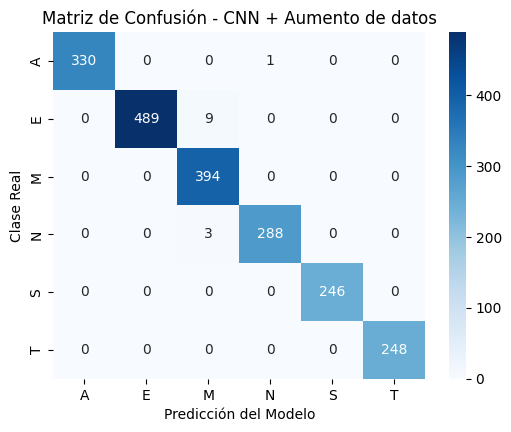

In [27]:
# Historial del modelo elegido, para dibujar sus curvas
historial_final = historial_cnn_optimo
for fila in resultados:
    if fila["modelo"] is modelo_final:
        historial_final = fila["historial"]

evaluar_modelo_completo(
    modelo_final, historial_final,
    x_test_final, y_test_cat, nombre_final
)

In [28]:
reporte = classification_report(
    y_true_final, y_pred_final,
    target_names=letras, output_dict=True, zero_division=0
)

tabla_clases = pd.DataFrame(reporte).T.loc[letras, ["recall", "f1-score", "support"]]
tabla_clases = tabla_clases.rename(columns={"f1-score": "f1", "support": "imagenes"})
tabla_clases["imagenes"] = tabla_clases["imagenes"].astype(int)
tabla_clases = tabla_clases.round(4)
display(tabla_clases)

print("Mejor recall:", tabla_clases["recall"].idxmax(),
      round(tabla_clases["recall"].max(), 4))
print("Peor recall :", tabla_clases["recall"].idxmin(),
      round(tabla_clases["recall"].min(), 4))
print("Brecha entre la mejor y la peor letra:",
      round(tabla_clases["recall"].max() - tabla_clases["recall"].min(), 4))

,recall,f1,imagenes
A,0.9970,0.9985,331
E,0.9819,0.9909,498
M,1.0000,0.9850,394
N,0.9897,0.9931,291
S,1.0000,1.0000,246
T,1.0000,1.0000,248


Mejor recall: M 1.0
Peor recall : E 0.9819
Brecha entre la mejor y la peor letra: 0.0181


Capa usada por Grad-CAM: conv2d_25


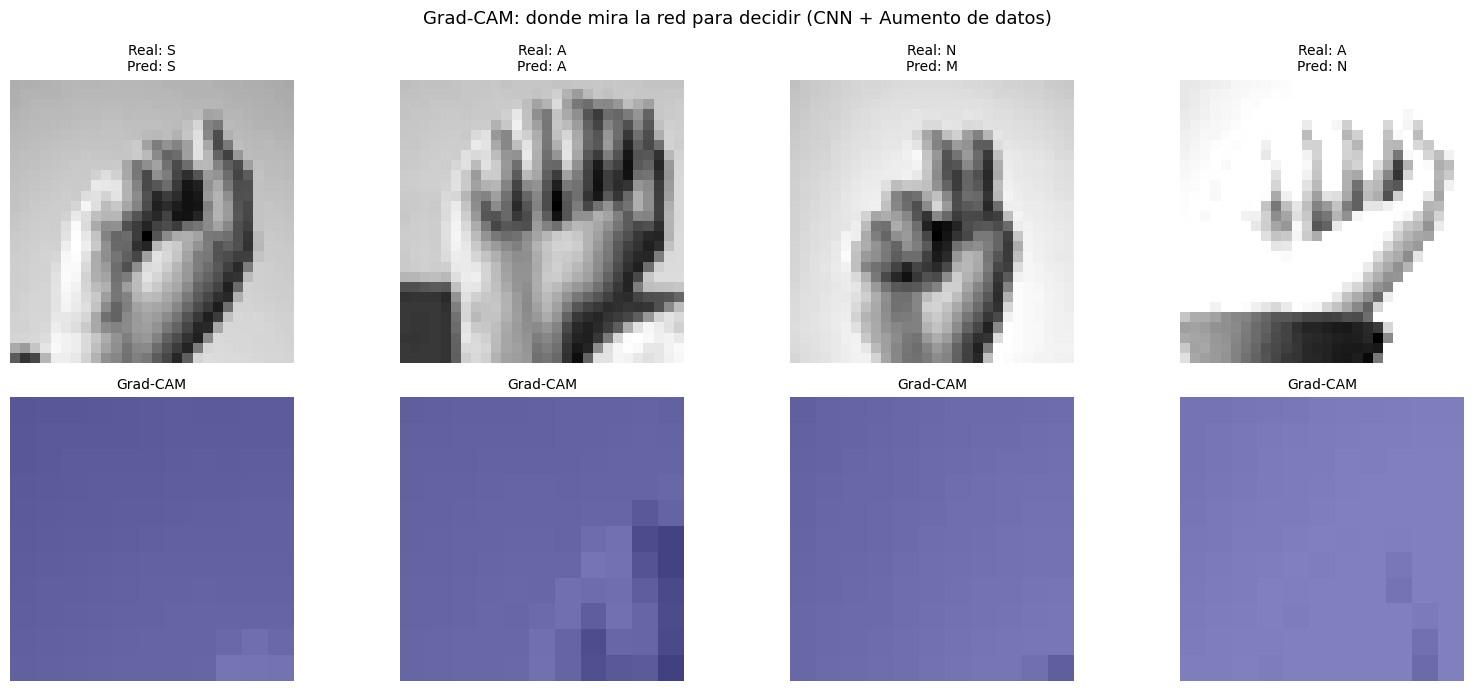

In [33]:

x_in = tf.keras.Input(shape=(28, 28, 1))


capa_cam = [c for c in modelo_final.layers if isinstance(c, tf.keras.layers.Conv2D)][-1].name


x = x_in
salida_conv = None

for capa in modelo_final.layers:
    x = capa(x)
    if capa.name == capa_cam:
        salida_conv = x


modelo_gradcam = tf.keras.models.Model(
    inputs=x_in,
    outputs=[salida_conv, x]
)

print("Capa usada por Grad-CAM:", capa_cam)


def mapa_gradcam(imagen, clase):
    """Devuelve un mapa de calor 0-1 con las zonas que mas pesaron para la clase."""
    with tf.GradientTape() as tape:
        salida_conv_val, prediccion = modelo_gradcam(imagen[np.newaxis, ...])
        puntaje = prediccion[:, clase]

    gradientes = tape.gradient(puntaje, salida_conv_val)


    pesos = tf.reduce_mean(gradientes, axis=(0, 1, 2))


    mapa = tf.reduce_sum(salida_conv_val[0] * pesos, axis=-1)
    mapa = tf.maximum(mapa, 0)
    mapa = mapa / (tf.reduce_max(mapa) + 1e-8)

    return mapa.numpy()


aciertos = np.where(y_pred_final == y_true_final)[0]
errores = np.where(y_pred_final != y_true_final)[0]

np.random.seed(semilla)
n_errores = min(2, len(errores))
seleccion = np.concatenate([
    np.random.choice(aciertos, 2, replace=False),
    np.random.choice(errores, n_errores, replace=False),
])

fig, axes = plt.subplots(2, len(seleccion), figsize=(4 * len(seleccion), 7))

for columna, idx in enumerate(seleccion):
    imagen = x_test_cnn[idx]
    clase_pred = y_pred_final[idx]
    mapa = mapa_gradcam(imagen, clase_pred)

    axes[0, columna].imshow(imagen.reshape(28, 28), cmap="gray")
    axes[0, columna].set_title(
        f"Real: {letras[y_true_final[idx]]}\nPred: {letras[clase_pred]}", fontsize=10
    )
    axes[0, columna].axis("off")

    axes[1, columna].imshow(imagen.reshape(28, 28), cmap="gray")
    axes[1, columna].imshow(mapa, cmap="jet", alpha=0.5)
    axes[1, columna].set_title("Grad-CAM", fontsize=10)
    axes[1, columna].axis("off")

plt.suptitle(f"Grad-CAM: donde mira la red para decidir ({nombre_final})", fontsize=13)
plt.tight_layout()
plt.show()

In [34]:
modelo_final.save("modelo_final.keras")
tabla_metricas.to_csv("metricas_modelos.csv")
print("Guardado: modelo_final.keras y metricas_modelos.csv")

modelo_final.summary()

inicio = time.time()
_ = modelo_final.predict(x_test_final, verbose=0)
tiempo_inferencia = time.time() - inicio

print(f"Tiempo de inferencia: {tiempo_inferencia:.2f} s para {len(x_test_final)} imagenes")
print(f"Promedio por imagen: {1000 * tiempo_inferencia / len(x_test_final):.2f} ms")

Guardado: modelo_final.keras y metricas_modelos.csv


Model: "sequential_20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ (None, 28, 28, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 28, 28, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 26, 26, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 11, 11, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_12 (Flatten)            │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 64)             │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_28 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_49 (Dense)                │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 170,260 (665.08 KB)

 Trainable params: 56,678 (221.40 KB)

 Non-trainable params: 224 (896.00 B)

 Optimizer params: 113,358 (442.81 KB)

Tiempo de inferencia: 0.41 s para 2008 imagenes
Promedio por imagen: 0.20 ms


# Impacto Ético

El desarrollo de herramientas de visión artificial para el reconocimiento del lenguaje de señas tiene un impacto social sumamente positivo, ya que promueve la inclusión y reduce las barreras de comunicación para la comunidad sorda en ámbitos como la salud, la educación y el sector público.

Sin embargo, desde la perspectiva ética y de ciencia de datos, es crucial señalar las siguientes consideraciones:
1. **Sesgo en los datos (Dataset):** El conjunto de datos *Sign Language MNIST* contiene imágenes muy homogéneas (fondos limpios, un solo tono de piel predominante y condiciones de iluminación controladas). Un modelo entrenado exclusivamente con estos datos podría fallar drásticamente en el mundo real con personas de distintos fenotipos, manos con accesorios o en entornos con fondos ruidosos.
2. **Privacidad:** La captura de imágenes de manos para sistemas de traducción automática en tiempo real requiere protocolos claros de privacidad y consentimiento por parte de los usuarios.
3. **Falsos negativos en contextos críticos:** En un entorno médico o de emergencias, un error de clasificación (un falso negativo) podría llevar a una mala interpretación de las necesidades del paciente. Por ende, este tipo de modelos debe ser una herramienta de apoyo y no un sustituto absoluto de un intérprete humano.

# Conclusiones